In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import copy

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

import mlflow
import mlflow.pytorch


from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from torch.utils.data import DataLoader, random_split


In [3]:
# i wont to test the pooling 



image = torch.randn(3, 16, 32,32)

pooling = nn.MaxPool2d(kernel_size = 2,
                     stride = 2,
                     padding = 0)
print('end=', pooling(image).shape)


# pooling does not change the number of channels, 
# it only changes the spatial dimensions (height and width) of the input image.nnels (3) but the height and width will be halved.

end= torch.Size([3, 16, 16, 16])


In [4]:
image = torch.tensor([
    [1.,2.,3.],
    [4.,5.,6.],
    [7.,8.,9.]
])
print("Image shape:", image.shape)
flat = image.view(-1)
print("Flattened shape:", flat.shape)


Image shape: torch.Size([3, 3])
Flattened shape: torch.Size([9])


In [5]:

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

# Two datasets with the same original training images
train_full = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=train_transform
)

val_full = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=test_transform
)

# Generate one reproducible split
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(50000, generator=generator).tolist()

train_indices = indices[:45000]
val_indices = indices[45000:]

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(val_full, val_indices)

# Official test dataset
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 45000
Validation samples: 5000
Test samples: 10000


In [6]:
# Input → Conv2d → ReLU → MaxPool2d → Conv2d → ReLU → MaxPool2d → Flatten → Linear
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.feature = nn.Sequential(   # layer 1
            nn.Conv2d(in_channels= 3, out_channels=16, kernel_size=3, stride=1 , padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # layer 2
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1 , padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
            
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=32 * 8 * 8 , out_features=10)
        )
        
        
    def forward(self, x):
        x = self.feature(x)
        return  self.classifier(x)
    
    


In [14]:
def log_cnn_experiment(
    model,
    params,
    metrics,
    run_name="SimpleCNN",
    confusion_matrix_path=None,
):
    """
    Log a PyTorch CNN experiment to MLflow.

    Args:
        model: Trained PyTorch model.
        params: Dictionary of training parameters.
        metrics: Dictionary of numerical metrics.
        run_name: Name of the MLflow run.
        confusion_matrix_path: Optional path to a saved plot.
    """

    started_run = mlflow.active_run() is None

    if started_run:
        mlflow.start_run(run_name=run_name)

    try:
        # Log hyperparameters and configuration
        mlflow.log_params(params)

        # Log evaluation and training metrics
        mlflow.log_metrics(metrics)

        # Save the trained model using pickle serialization.
        # MLflow 3 defaults to pt2, which requires an input example and signature.
        mlflow.pytorch.log_model(
            model,
            name="simple_cnn_model",
            serialization_format="pickle",
        )

        # Save additional artifacts
        if confusion_matrix_path is not None:
            mlflow.log_artifact(confusion_matrix_path)

        active_run = mlflow.active_run()
        if active_run is not None:
            print(f"MLflow Run ID: {active_run.info.run_id}")
        print("Experiment logged successfully.")
    finally:
        if started_run:
            mlflow.end_run()


In [15]:


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SimpleCNN().to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

num_epochs = 20
patience = 3

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(num_epochs):

    # -------------------------
    # 1. Training
    # -------------------------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = 100 * train_correct / train_total
    
    log_cnn_experiment(
       model,
         {
              "learning_rate": 0.001,
              "batch_size": 128,
              "num_epochs": num_epochs,
              "patience": patience
         },
         {
              "train_loss": train_loss,
              "train_accuracy": train_acc
         }
         
    )
    # -------------------------
    # 2. Validation
    # -------------------------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = 100 * val_correct / val_total

    # -------------------------
    # 3. Save best checkpoint
    # -------------------------
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_state,
            "best_simple_cnn.pth"
        )

        epochs_without_improvement = 0
        status = "Best model saved"

    else:
        epochs_without_improvement += 1
        status = (
            f"No improvement: "
            f"{epochs_without_improvement}/{patience}"
        )

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"{status}"
    )

    # -------------------------
    # 4. Early stopping
    # -------------------------
    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore the best weights
if best_model_state is not None:
    model.load_state_dict(best_model_state)

elapsed_time = time.time() - start_time

print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {elapsed_time:.2f} seconds")


2026/10/10 23:06:13 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 23:06:20 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


MLflow Run ID: 07241326c79c453091d141de1d3babec
Experiment logged successfully.
Epoch [1/20] Train Loss: 1.7147 | Train Acc: 38.18% | Val Loss: 1.4426 | Val Acc: 48.66% | Best model saved


2026/10/10 23:06:37 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 23:06:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


MLflow Run ID: b5f0f3a455974f53965793b9779446cb
Experiment logged successfully.
Epoch [2/20] Train Loss: 1.4674 | Train Acc: 47.35% | Val Loss: 1.3071 | Val Acc: 54.52% | Best model saved


2026/10/10 23:06:58 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 23:07:01 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


...

MLflow Run ID: c5f44848e216452998bb8f43438c1f1a
Experiment logged successfully.
Epoch [18/20] Train Loss: 1.0192 | Train Acc: 64.38% | Val Loss: 0.8860 | Val Acc: 69.50% | Best model saved


2026/10/10 23:13:03 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 23:13:07 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


MLflow Run ID: 45e0a5dcd60743aa99a005390dff9594
Experiment logged successfully.
Epoch [19/20] Train Loss: 1.0119 | Train Acc: 64.92% | Val Loss: 0.8803 | Val Acc: 69.62% | Best model saved


2026/10/10 23:13:27 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/10 23:13:31 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


MLflow Run ID: ea11c2221fce4ec78eac66a3a9399314
Experiment logged successfully.
Epoch [20/20] Train Loss: 1.0039 | Train Acc: 64.84% | Val Loss: 0.8699 | Val Acc: 70.00% | Best model saved
Best Validation Loss: 0.8699
Training Time: 455.90 seconds


In [12]:


def evaluate_accuracy(model, loader, device):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


# Load the exact checkpoint selected during training
state = torch.load(
    "best_simple_cnn.pth",
    map_location=device,
    weights_only=True,
)
model.load_state_dict(state)
model.to(device)

val_accuracy = evaluate_accuracy(model, val_loader, device)
test_accuracy = evaluate_accuracy(model, test_loader, device)

print(f"Validation Accuracy: {val_accuracy:.2f}%")
print(f"Test Accuracy:       {test_accuracy:.2f}%")
print(f"Difference:          {val_accuracy - test_accuracy:.2f} percentage points")

# Validation Accuracy: 63.54%
# Test Accuracy:       69.51%
# Difference:          -5.97 percentage points



# Validation Accuracy: 68.24%
# Test Accuracy:       68.50%
# Difference:          -0.26 percentage points

Validation Accuracy: 68.24%
Test Accuracy:       68.50%
Difference:          -0.26 percentage points


In [14]:
state = torch.load(
    "best_simple_cnn.pth",
    map_location=device,
    weights_only=True,
)

model.load_state_dict(state)
model.to(device)
model.eval()

val_correct = 0
val_total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)

print(f"Correct: {val_correct}/{val_total}")
print(f"Validation Accuracy: {100 * val_correct / val_total:.2f}%")


# Correct: 3206/5000
# Validation Accuracy: 64.12%

Correct: 3412/5000
Validation Accuracy: 68.24%


Test Accuracy: 68.50%
              precision    recall  f1-score   support

    airplane     0.6958    0.6840    0.6899      1000
  automobile     0.8008    0.8080    0.8044      1000
        bird     0.5165    0.5620    0.5383      1000
         cat     0.5480    0.4970    0.5212      1000
        deer     0.6640    0.5810    0.6197      1000
         dog     0.6581    0.5660    0.6086      1000
        frog     0.7087    0.8100    0.7559      1000
       horse     0.6977    0.7730    0.7334      1000
        ship     0.8166    0.7660    0.7905      1000
       truck     0.7374    0.8030    0.7688      1000

    accuracy                         0.6850     10000
   macro avg     0.6844    0.6850    0.6831     10000
weighted avg     0.6844    0.6850    0.6831     10000



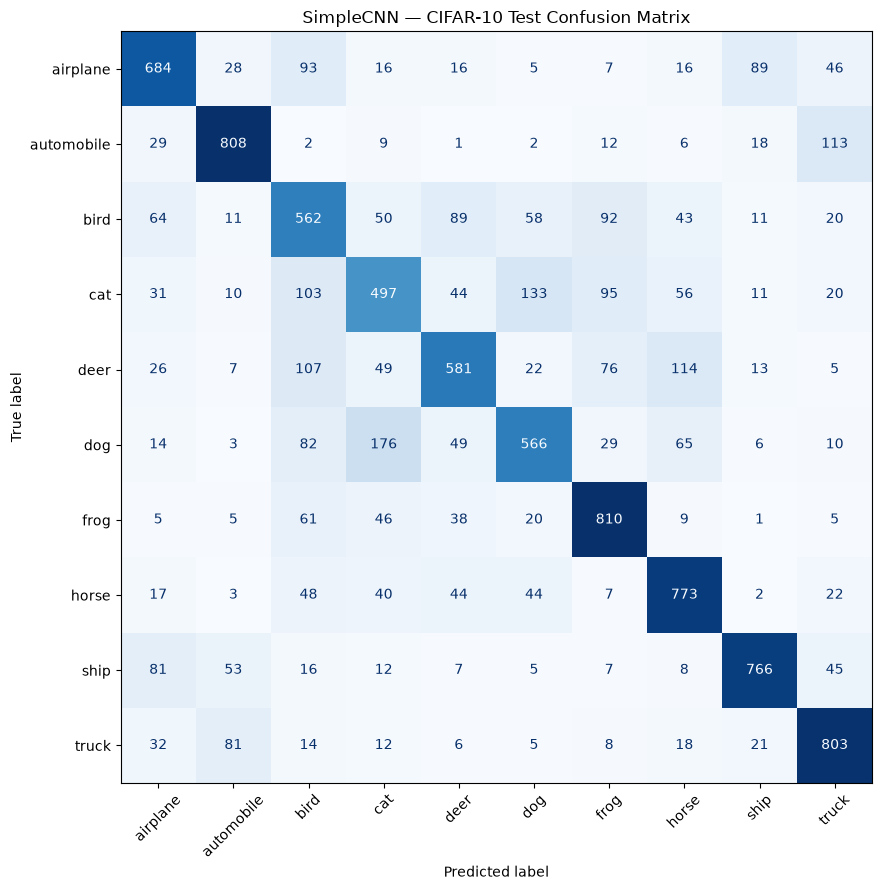

In [12]:


# Load the best checkpoint
state = torch.load(
    "best_simple_cnn.pth",
    map_location=device,
    weights_only=True,
)

model.load_state_dict(state)

model.to(device)

model.eval()

CLASS_NAMES = test_dataset.classes
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

# Overall test accuracy
correct = sum(
    p == y for p, y in zip(all_predictions, all_labels)
)
test_accuracy = 100 * correct / len(all_labels)

print(f"Test Accuracy: {test_accuracy:.2f}%")

# Precision, Recall, F1-score
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

# Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

fig, ax = plt.subplots(figsize=(11, 9))
display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
)
plt.title("SimpleCNN — CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.show()
